In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
project_path = "/content/drive/MyDrive/LLM_Smart_City"
df = pd.read_csv(f"{project_path}/smart_city_ml_dataset.csv")

df.head()

,timestamp,traffic_congestion_level,energy_consumption_mw,crime_index,air_quality_index,water_consumption_mld
0,01-01-2025 00:00,61,535,62,90,57
1,01-01-2025 01:00,24,536,59,76,181
2,01-01-2025 02:00,81,262,66,178,153
3,01-01-2025 03:00,70,762,27,109,181
4,01-01-2025 04:00,30,774,13,147,233


In [ ]:
df.describe()

,traffic_congestion_level,energy_consumption_mw,crime_index,air_quality_index,water_consumption_mld
count,200.000000,200.0000,200.000000,200.000000,200.000000
mean,55.210000,462.0050,44.670000,142.245000,166.550000
std,27.169779,191.2312,23.873012,64.630958,74.839376
min,10.000000,151.0000,5.000000,30.000000,50.000000
25%,32.750000,296.7500,23.000000,83.750000,103.000000
50%,56.500000,449.0000,43.000000,144.000000,160.500000
75%,76.000000,623.0000,65.000000,195.000000,233.250000
max,99.000000,791.0000,89.000000,249.000000,299.000000


In [ ]:
cities = ["Hyderabad", "Bengaluru", "Chennai", "Mumbai", "Delhi"]

df["city_name"] = np.random.choice(cities, size=len(df))
df.head()

,timestamp,traffic_congestion_level,energy_consumption_mw,crime_index,air_quality_index,water_consumption_mld,city_name
0,01-01-2025 00:00,61,535,62,90,57,Chennai
1,01-01-2025 01:00,24,536,59,76,181,Mumbai
2,01-01-2025 02:00,81,262,66,178,153,Mumbai
3,01-01-2025 03:00,70,762,27,109,181,Hyderabad
4,01-01-2025 04:00,30,774,13,147,233,Bengaluru


In [ ]:
def create_risk_label(value, low, high):
    if value >= high:
        return 2   # High
    elif value >= low:
        return 1   # Medium
    else:
        return 0   # Low

df["traffic_risk"] = df["traffic_congestion_level"].apply(
    lambda x: create_risk_label(x, 40, 70)
)

df["energy_risk"] = df["energy_consumption_mw"].apply(
    lambda x: create_risk_label(x, 300, 600)
)

df["crime_risk"] = df["crime_index"].apply(
    lambda x: create_risk_label(x, 30, 60)
)

df["air_risk"] = df["air_quality_index"].apply(
    lambda x: create_risk_label(x, 100, 180)
)

df["water_risk"] = df["water_consumption_mld"].apply(
    lambda x: create_risk_label(x, 120, 220)
)

df.head()

,timestamp,traffic_congestion_level,energy_consumption_mw,crime_index,air_quality_index,water_consumption_mld,city_name,traffic_risk,energy_risk,crime_risk,air_risk,water_risk
0,01-01-2025 00:00,61,535,62,90,57,Chennai,1,1,2,0,0
1,01-01-2025 01:00,24,536,59,76,181,Mumbai,0,1,1,0,1
2,01-01-2025 02:00,81,262,66,178,153,Mumbai,2,0,2,1,1
3,01-01-2025 03:00,70,762,27,109,181,Hyderabad,2,2,0,1,1
4,01-01-2025 04:00,30,774,13,147,233,Bengaluru,0,2,0,1,2


In [ ]:
selected_city = "Hyderabad"

city_df = df[df["city_name"] == selected_city]
city_df.head()

,timestamp,traffic_congestion_level,energy_consumption_mw,crime_index,air_quality_index,water_consumption_mld,city_name,traffic_risk,energy_risk,crime_risk,air_risk,water_risk
3,01-01-2025 03:00,70,762,27,109,181,Hyderabad,2,2,0,1,1
15,01-01-2025 15:00,97,279,67,172,100,Hyderabad,2,0,2,1,0
22,01-01-2025 22:00,42,272,55,173,110,Hyderabad,1,0,1,1,0
30,02-01-2025 06:00,69,758,80,131,139,Hyderabad,1,2,2,1,1
41,02-01-2025 17:00,60,297,14,215,96,Hyderabad,1,0,0,2,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

def train_model(feature, target):
    X = df[[feature]]
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    return model

traffic_model = train_model("traffic_congestion_level", "traffic_risk")
energy_model  = train_model("energy_consumption_mw", "energy_risk")
crime_model   = train_model("crime_index", "crime_risk")
air_model     = train_model("air_quality_index", "air_risk")
water_model   = train_model("water_consumption_mld", "water_risk")

print("✅ All AI models trained successfully")

✅ All AI models trained successfully


In [ ]:
RISK_MAP = {0: "Low", 1: "Medium", 2: "High"}

class CityAgent:
    def __init__(self, model, feature):
        self.model = model
        self.feature = feature

    def analyze(self, row):
        value = row[self.feature]
        pred = self.model.predict(
            pd.DataFrame([[value]], columns=[self.feature])
        )[0]

        return value, RISK_MAP[pred]

In [ ]:
# Traffic decision model
selected_city = "Hyderabad"
print("City:", selected_city)
X = city_df[features]
y = city_df["traffic_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

traffic_model = RandomForestClassifier(random_state=42)
traffic_model.fit(X_train, y_train)

preds = traffic_model.predict(X_test)
print("Traffic Accuracy:", accuracy_score(y_test, preds))

latest_data = city_df.iloc[-1][features].values.reshape(1, -1)
risk = traffic_model.predict(latest_data)[0]

traffic_decision = {
    0: "Normal traffic – no action required",
    1: "Moderate traffic – optimize signals",
    2: "High traffic – deploy traffic police"
}

print("Traffic AI Decision:", traffic_decision[risk])

City: Hyderabad
Traffic Accuracy: 1.0
Traffic AI Decision: Moderate traffic – optimize signals


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# Energy decision model
y = city_df["energy_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

energy_model = RandomForestClassifier(random_state=42)
energy_model.fit(X_train, y_train)

preds = energy_model.predict(X_test)
print("Energy Accuracy:", accuracy_score(y_test, preds))

risk = energy_model.predict(latest_data)[0]

energy_decision = {
    0: "Normal energy usage",
    1: "Load balancing required",
    2: "Emergency power optimization"
}

print("Energy AI Decision:", energy_decision[risk])

Energy Accuracy: 0.5555555555555556
Energy AI Decision: Normal energy usage


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# crime decision model
y = city_df["crime_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

crime_model = RandomForestClassifier(random_state=42)
crime_model.fit(X_train, y_train)

preds = crime_model.predict(X_test)
print("Crime Accuracy:", accuracy_score(y_test, preds))

risk = crime_model.predict(latest_data)[0]

crime_decision = {
    0: "Normal surveillance",
    1: "Increase patrols",
    2: "Emergency police deployment"
}

print("Crime AI Decision:", crime_decision[risk])


Crime Accuracy: 0.4444444444444444
Crime AI Decision: Increase patrols


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# Air quality decision model
y = city_df["air_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

air_model = RandomForestClassifier(random_state=42)
air_model.fit(X_train, y_train)

preds = air_model.predict(X_test)
print("Air Quality Accuracy:", accuracy_score(y_test, preds))

risk = air_model.predict(latest_data)[0]

air_decision = {
    0: "Air quality is safe",
    1: "Pollution alert",
    2: "Health emergency warning"
}

print("Air Quality AI Decision:", air_decision[risk])

Air Quality Accuracy: 0.3333333333333333
Air Quality AI Decision: Health emergency warning


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# Water management decision model
y = city_df["water_risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

water_model = RandomForestClassifier(random_state=42)
water_model.fit(X_train, y_train)

preds = water_model.predict(X_test)
print("Water Accuracy:", accuracy_score(y_test, preds))

risk = water_model.predict(latest_data)[0]

water_decision = {
    0: "Normal water usage",
    1: "Water conservation advised",
    2: "Water usage restrictions"
}

print("Water AI Decision:", water_decision[risk])

Water Accuracy: 0.3333333333333333
Water AI Decision: Normal water usage


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
class CityCoordinator:
    def __init__(self):
        self.traffic = CityAgent(traffic_model, "traffic_congestion_level")
        self.energy  = CityAgent(energy_model, "energy_consumption_mw")
        self.crime   = CityAgent(crime_model, "crime_index")
        self.air     = CityAgent(air_model, "air_quality_index")
        self.water   = CityAgent(water_model, "water_consumption_mld")

    def process(self, row):
        return {
            "Traffic": self.traffic.analyze(row),
            "Energy": self.energy.analyze(row),
            "Crime": self.crime.analyze(row),
            "Air Quality": self.air.analyze(row),
            "Water": self.water.analyze(row)
        }

In [ ]:
# List of domains
domains = ["Traffic", "Energy", "Crime", "Air Quality", "Water"]

ACTION_MAP = {
    0: "Normal condition",
    1: "Monitoring required",
    2: "Immediate action required"
}

# Calculate overall risk
overall_risk = {
    "Traffic": df["traffic_risk"].mode()[0],
    "Energy": df["energy_risk"].mode()[0],
    "Crime": df["crime_risk"].mode()[0],
    "Air Quality": df["air_risk"].mode()[0],
    "Water": df["water_risk"].mode()[0]
}

# Map risk to action
overall_action = {domain: ACTION_MAP[risk] for domain, risk in overall_risk.items()}

print("✅ Overall Smart City Risk Summary:\n")

for domain in domains:
    print(domain)
    print("Overall Risk:", overall_risk[domain])
    print("Recommended Action:", overall_action[domain])
    print()

✅ Overall Smart City Risk Summary:

Traffic
Overall Risk: 2
Recommended Action: Immediate action required

Energy
Overall Risk: 1
Recommended Action: Monitoring required

Crime
Overall Risk: 1
Recommended Action: Monitoring required

Air Quality
Overall Risk: 1
Recommended Action: Monitoring required

Water
Overall Risk: 1
Recommended Action: Monitoring required



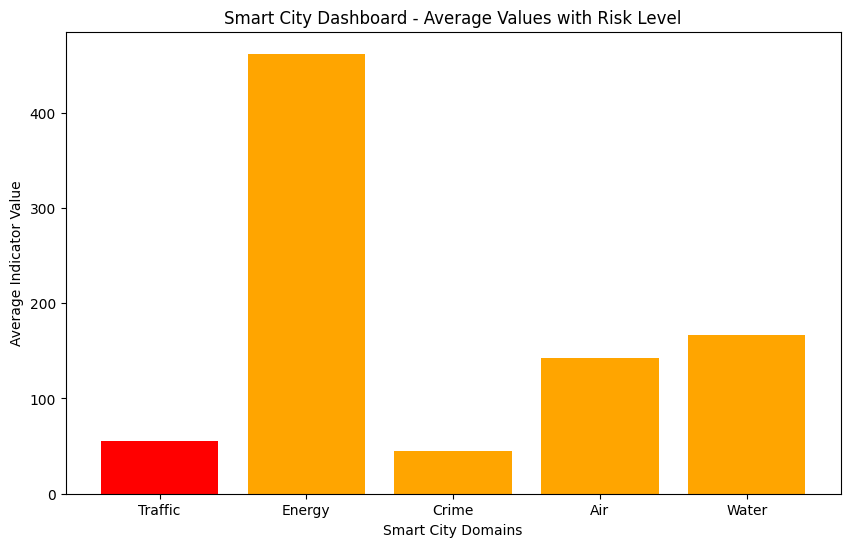

In [ ]:
# Calculate average values for each domain
avg_values = {
    "Traffic": df["traffic_congestion_level"].mean(),
    "Energy": df["energy_consumption_mw"].mean(),
    "Crime": df["crime_index"].mean(),
    "Air": df["air_quality_index"].mean(),
    "Water": df["water_consumption_mld"].mean()
}

# Function to find most frequent risk
def dominant_risk(col):
    return df[col].mode()[0]

dominant_risks = {
    "Traffic": dominant_risk("traffic_risk"),
    "Energy": dominant_risk("energy_risk"),
    "Crime": dominant_risk("crime_risk"),
    "Air": dominant_risk("air_risk"),
    "Water": dominant_risk("water_risk")
}

# Convert risk number to label
risk_map = {0: "Low", 1: "Medium", 2: "High"}

dominant_risks = {k: risk_map[v] for k, v in dominant_risks.items()}

# Assign colors based on risk
color_map = {"Low": "green", "Medium": "orange", "High": "red"}
colors = [color_map[dominant_risks[domain]] for domain in avg_values.keys()]

# Plot graph
plt.figure(figsize=(10,6))
plt.bar(avg_values.keys(), avg_values.values(), color=colors)
plt.title("Smart City Dashboard - Average Values with Risk Level")
plt.ylabel("Average Indicator Value")
plt.xlabel("Smart City Domains")
plt.show()